In [3]:
import json
import os
import cv2
import json
import fastwer
import shutil
import pyewts
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from evaluate import load
from natsort import natsorted
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference
from IPython.display import Image as ShowImage
from Exporter import PageXMLExporter
from Utils import create_dir, get_line_images_from_line_data, rotate_from_angle, get_random_color, read_lines_from_file, get_file_name, get_lines_from_page, prepare_ocr_image2, get_line_bbox_centers, group_bbox_centers, resize_to_height, get_line_treshold

In [1]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4, axis="off"):
    plt.figure(figsize=(18, 9))
    plt.axis(axis)
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)


def generate_line_image(image, contour, kernel: tuple = (10, 14), iterations: int = 4):
    image_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    cv2.drawContours(image_mask, [contour], contourIdx=-1, color=(255, 255, 255), thickness=-1)
    dilate_k = np.ones(kernel, dtype=np.uint8)
    kernel_iterations = iterations

    image_mask = cv2.dilate(image_mask, dilate_k, iterations=kernel_iterations)
    image_masked = cv2.bitwise_and(image, image, mask=image_mask)

    cropped_img = np.delete(image_masked, np.where(~image_masked.any(axis=1))[0], axis=0)
    cropped_img = np.delete(cropped_img,np.where(~cropped_img.any(axis=0))[0], axis=1)   
    #display(Image.fromarray(cropped_img))

    #indices = np.where(cropped_img[:, :]==0)
    #clear = cropped_img.copy()
    #clear[indices[0], indices[1]] = [255, 255, 255]
    #clear_bw = cv2.cvtColor(clear, cv2.COLOR_BGR2GRAY)
    #_ ,thresh = cv2.threshold(clear_bw, 170, 255,cv2.THRESH_BINARY)

    return cropped_img

NameError: name 'np' is not defined

In [3]:
layout_config = "Models/LayoutModels/Classic/LA_v2_2024-1-22_6-36/model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

models_path = "Models/OCRModels"
dataset = "DergeTenjur"
chkpt_path = "2024_1_30_9_38"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [4]:
data_root = "J:/Datasets/Tibetan/OCR/Mipham"
images = natsorted(glob(f"{data_root}/pages/*.jpg"))
transcriptions = natsorted(glob(f"{data_root}/transcriptions/*.txt"))

print(f"Images: {len(images)}, Transcriptions: {len(transcriptions)}")

Images: 21341, Transcriptions: 21341


1-4-166b
6
པ་དང་ཡོངས་སུ་བསྔོ་བ་དང་ཚོགས་གཉིས་དང་བསམ་གྱིས་མི་ཁྱབ་པའི་ཆོས་ཉིད་ཀྱང་ཡིན་ནོ།  །ཇི་སྐད་དུ་རིན་པོ་ཆེའི་ཕྲེང་བ་ལས། ཉན་ཐོས་ཐེག་པ་དེ་ལས་ནི།  །བྱང་ཆུབ་སེམས་
དཔའི་སྨོན་ལམ་དང་།  །སྤྱོད་པ་ཡོངས་བསྔོ་མ་བཤད་དེས།  །བྱང་ཆུབ་སེམས་དཔར་ག་ལ་འགྱུར།  །བྱང་ཆུབ་སྤྱོད་ལ་གནས་པའི་དོན།  །མདོ་སྡེ་ལས་ནི་བཀའ་མ་སྩལ།  །ཐེག་
པ་ཆེ་ལས་བཀའ་སྩལ་པ།  །དེ་ཕྱིར་མཁས་པ་རྣམས་ཀྱིས་ཟུངས།  །ཞེས་གསུངས་སོ།  །ཆོས་ཀྱི་བདག་མེད་པ་གསལ་བར་བྱ་བའི་ཕྱིར། ཐེག་པ་ཆེན་པོ་བསྟན་པ་ཡང་རིགས་པ་ཉིད་དེ།
རྒྱས་པར་བསྟན་པ་བརྗོད་པར་འདོད་པའི་ཕྱིར་རོ།  །ཉན་ཐོས་ཀྱི་ཐེག་པ་ལས་ནི་ཆོས་ཀྱི་བདག་མེད་པ་མདོར་མཚོན་པ་ཙམ་ཞིག་ཏུ་ཟད་དོ།  །ཇི་སྐད་དུ་སློབ་དཔོན་གྱི་ཞལ་སྔ་ནས་ཀྱིས།
མཚན་མ་མེད་པ་མ་རྟོགས་པར།  །ཁྱོད་ཀྱིས་ཐར་པ་མེད་པར་གསུངས།  །དེ་ཕྱིར་ཁྱོད་ཀྱིས་ཐེག་ཆེན་ལས།  །དེ་ནི་ཚང་པར་བསྟན་པ་ལགས།  །ཞེས་གསུངས་སོ།  །ཞར་ལ་འོང་བས་
ཆོག་གོ། དེ་ཉིད་ཀྱི་ཕྱིར་བློ་མ་དཀྲུགས་པ་རྣམས་ཀྱིས་རང་ཉིད་ཀྱི་དེ་ཁོ་ན་ཉིད་ཁོང་དུ་ཆུད་པར་ནུས་པས་དཀྱུས་མ་ཉིད་བརྗོད་པར་བྱའོ།  །ཞེས་གསུངས་པའི་དོན། འོ་ན་ཉན་རང་གི་


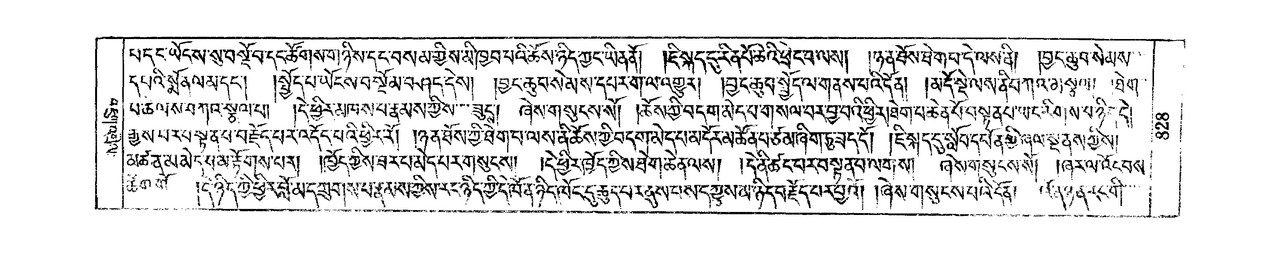

In [20]:
sample_idx = 824
image_name = get_file_name(images[sample_idx])
print(image_name)
sample_image = images[sample_idx]
sample_transcription = transcriptions[sample_idx]

lines = get_lines_from_page(sample_transcription)
print(len(lines))
for line in lines:
    print(line)

ShowImage(sample_image)

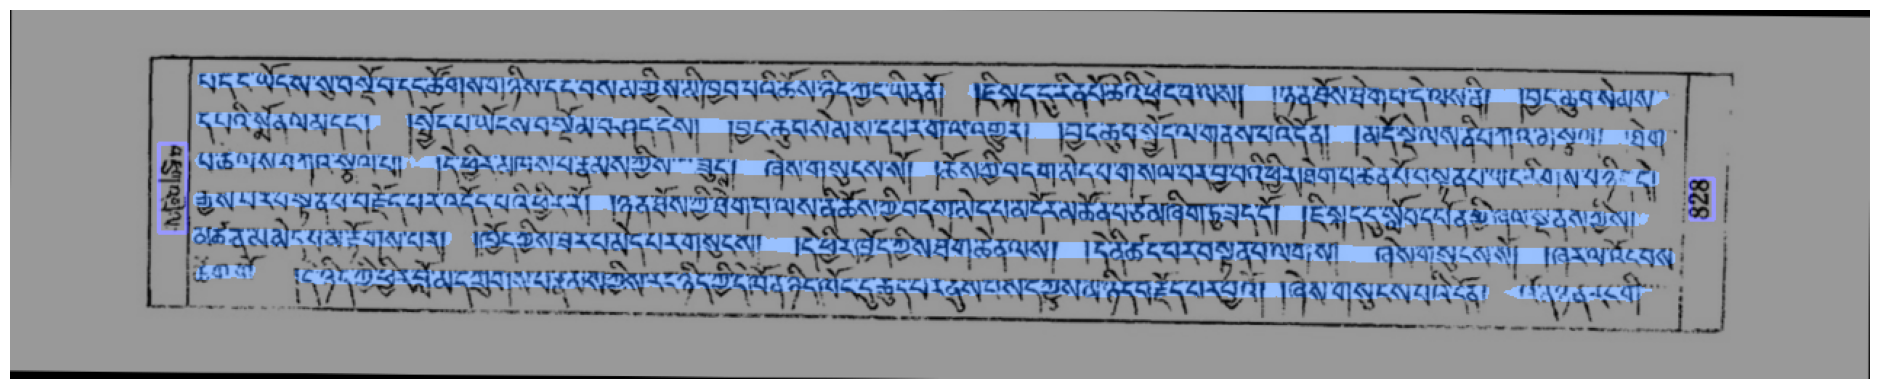

In [15]:
image_name = os.path.basename(sample_image).split(".")[0]
_img = cv2.imread(sample_image)
# layout_inference
layout_data, preview_img = layout_inference.predict(_img)
show_image(preview_img)

6


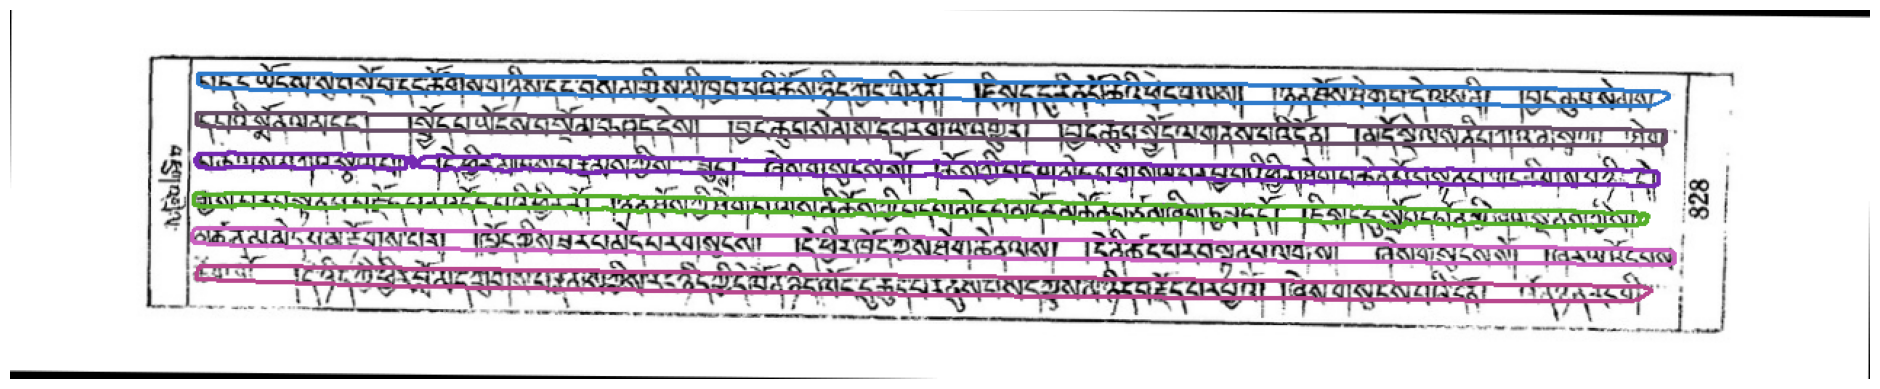

In [19]:
sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()
color = get_random_color()
print(len(layout_data.lines))
for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

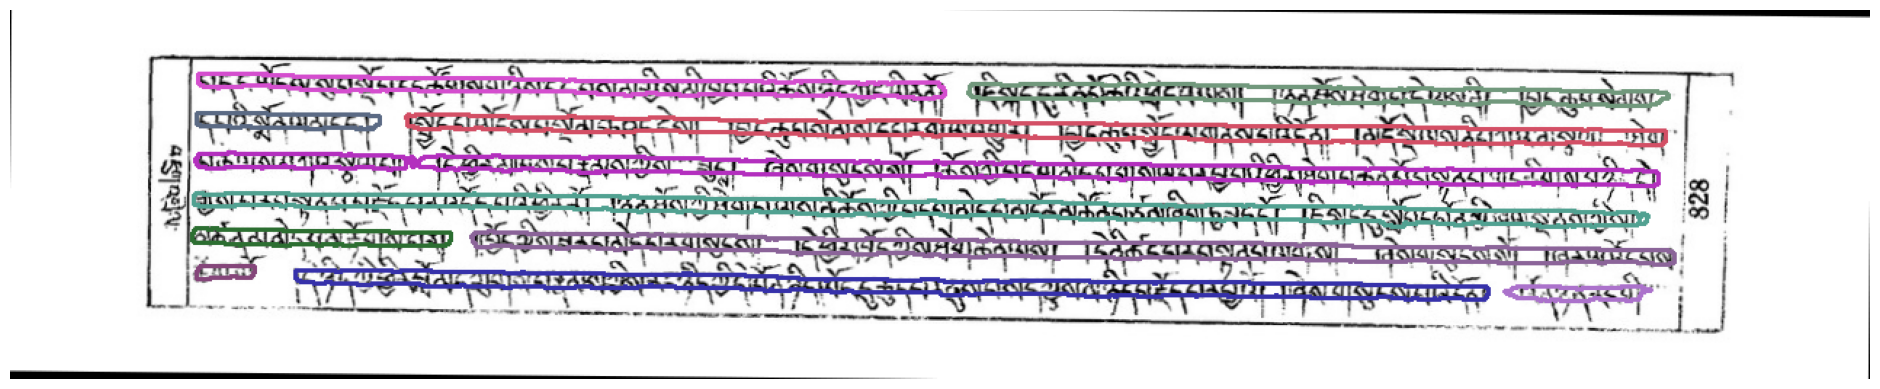

In [16]:
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [9]:
r_img = rotate_from_angle(_img, layout_data.rotation)
line_threshold = get_line_treshold(layout_data.predictions["lines"])
bbox_centers = get_line_bbox_centers(layout_data)
sorted_bbox_centers = group_bbox_centers(bbox_centers, line_threshold=line_threshold)

image_lines = []

for center_group in sorted_bbox_centers:
    sorted_line_stack = []
    for center in center_group:
        for line in layout_data.lines:
            if center == line.center:
                sorted_line_stack.append(line)
    
    img_stack = []

    for line in sorted_line_stack:
        # TODO: maybe use here the bbox of each segment and extend it using the calculated line threshold instead of dilating the segment, which turns out to be not so stable
        img = generate_line_image(r_img, line.contour, kernel=(10, 10), iterations=2)
        img_stack.append(img)

    max_y = min(x.shape[0] for x in img_stack) # or max?
    img_stack = [resize_to_height(x, target_height=max_y) for x in img_stack]
    stacked_line = np.hstack(img_stack)

    image_lines.append(stacked_line)

np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in image_lines]
            
np_img_batch = np.array(np_img_batch, np.float32)
print(np_img_batch.shape)

(7, 1, 80, 2000)


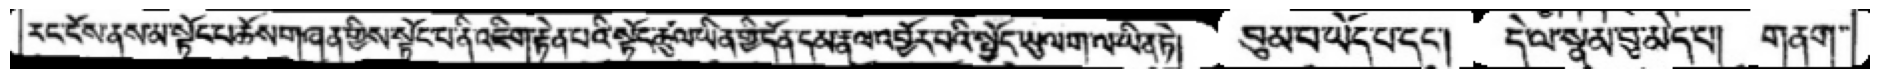

In [11]:
show_image(image_lines[1])

In [215]:
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)

kyi /tman mnas pas spyad //sna tshogs bstan bcas bslab bya zhing //yoan tan can la bstan par bya//bstan bcos rnams lam byung na//blo gros chung ngu'i shes pa yis//blang dor rgya chen 
mi 'byed pas//bka' dang dgongs 'grel blta bar bya//yon tan bslab pa'i dus nyid na//che tshugs spangs te bla ma bsten//dam pa rnams la bstan byas na//yon tan dbyar gyi chu bzhin 'phel//mthong dang //
ma mthong yon tan ni//kun gyi rtsa ba shes rab yin//shes rab med na yul 'khor la//byams pa tsam gyis skyong mi nus//shes rab ldan pas brtsams byas na//mi 'grub pa ni gang yang med//shes /
rab stobs kyis sangs rgyas kyang //'grub par nus na gzhan lta ci//shes rab rgya cher 'phel ba'i sgra//thos pa yin pa de yi phyir//'bad de thos pa mi 'tshal bar//mnhog chung bya bas cizhag pa//chos den 
'dod dang thar pa yi//'byung gnas chen po rig pa yin//rig pa spel ba'i gzhung bzang ba//byin kyang mi mkho phyugs min nam//shes rab ldan pa gcig pus kyang //stobs ldan dgra tshogs pham par nas//
'od zer mchog tu 'phags pa yi//n

### run on entire collection*

In [5]:
from evaluate import load
converter = pyewts.pyewts()
cer_scorer = load("cer")

In [6]:
score_dict = {}
mismatched_pages = []

for idx, (sample_image, sample_transcription) in tqdm(enumerate(zip(images[2780:], transcriptions[2780:])), total=len(images[2780:])):
    
    label_lines = get_lines_from_page(sample_transcription)
    image_name = os.path.basename(sample_image).split(".")[0]
    _img = cv2.imread(sample_image)
    # layout_inference
    layout_data, preview_img = layout_inference.predict(_img)

    sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=True)
    r_img = rotate_from_angle(_img, layout_data.rotation)
    layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=16, calculate_iterations=False)
    #rev_images = list(reversed(layout_line_images))

    np_img_batch = [
                prepare_ocr_image2(
                    x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
                ) for x in layout_line_images]
                
    np_img_batch = np.array(np_img_batch, np.float32)
    predicted_lines, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")

    if len(predicted_lines) == len(label_lines):
        for l_idx, (pred_line, label_line) in enumerate(zip(predicted_lines, label_lines)):
            label_line = converter.toWylie(label_line)
            label_line = label_line.replace("/__/", "//")

            cer_score = cer_scorer.compute(predictions=[pred_line], references=[label_line])
            score_dict[f"{image_name}_{l_idx}"] = (label_line, round(cer_score, 3))
    else:
        mismatched_pages.append(image_name)



  0%|          | 0/18561 [00:00<?, ?it/s]

  0%|          | 1/18561 [00:08<46:22:24,  8.99s/it]d:\Github\OCR-Inference\venv\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
d:\Github\OCR-Inference\venv\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 18561/18561 [2:45:57<00:00,  1.86it/s]  


In [7]:
score_dict_out = f"{data_root}/scores_pt2.txt"

with open(score_dict_out, "w", encoding="utf-8") as f:
    for k, v in score_dict.items():
        lbl, score = v
        f.write(f"{k}: {score}, {lbl}\n")

In [8]:
mismatched_out = f"{data_root}/mismatched_pt2.txt"

with open(mismatched_out, "w", encoding="utf-8") as f:
    for page in mismatched_pages:
        f.write(f"{page}\n")

In [9]:
len(mismatched_out)

49